In [4]:
import decoupler as dc
import matplotlib.pyplot as plt
from pathlib import Path
from pydeseq2.dds import DeseqDataSet, DefaultInference
from pydeseq2.ds import DeseqStats
import scanpy as sc

/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
script_dir = Path.cwd()
project_dir = script_dir.parent
data_filepath = project_dir / "processed_data" / "uc_Epi_clustered.h5ad"

sc_adata = sc.read_h5ad(data_filepath)

In [8]:
sc_adata

AnnData object with n_obs × n_vars = 69313 × 2000
    obs: 'samples', 'Cluster', 'Subject', 'Health', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'cell_type_group', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Cluster_colors', 'Health_colors', 'cell_type_group_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_nn10_pc10_res0.25', 'leiden_nn10_pc10_res0.5', 'leiden_nn10_pc10_res0.75', 'leiden_nn10_pc10_res1', 'leiden_nn10_pc10_res1.5', 'leiden_nn10_pc10_res2', 'leiden_nn10_pc15_res0.25', 'leiden_nn10_p

Relevant data in this object:

- obs: cell_type_group, leiden, Subject, Health

The goal of this DEA is to identify genes that differentiate disease state in each cell type. We will start by pseudobulking the broad cell type annotations (cell_type_group) and then mapping the expression of the top DE genes back to the tSNE space, and see how they are distributed across clusters (leiden).

The output pseudobulked adata object can be input to our prediction model. 

Number of pseudobulked cells: 917
Health
Healthy         336
Non-inflamed    315
Inflamed        266
Name: count, dtype: int64


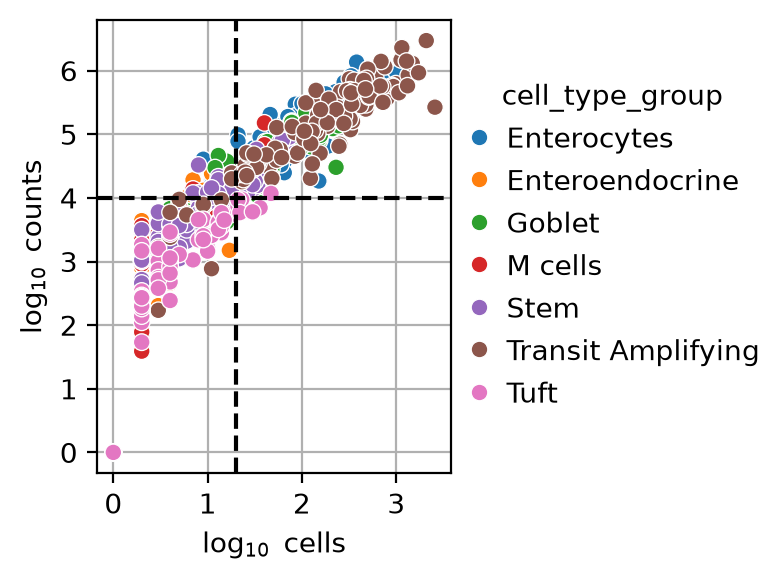

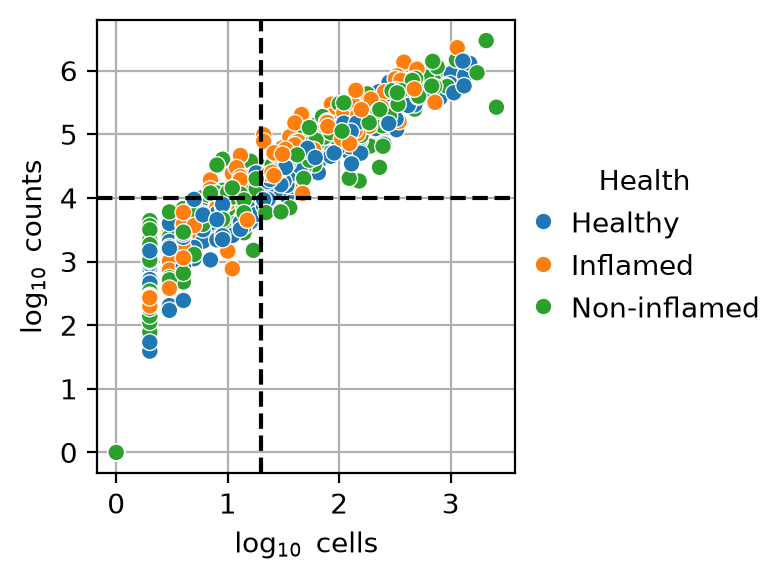

In [42]:
# pseudobulk from the raw counts, not normalized ones
# new object will have one observation per cell type per sample, rather than individual observations per cell type per sample
pb_adata = dc.pp.pseudobulk(adata=sc_adata, layer="counts", sample_col="samples", groups_col="cell_type_group", mode="sum")
print("Number of pseudobulked cells:", pb_adata.shape[0])
print(pb_adata.obs['Health'].value_counts())

dc.pl.filter_samples(pb_adata, groupby=["cell_type_group"], min_cells=20, min_counts=10000)
dc.pl.filter_samples(pb_adata, groupby=["Health"], min_cells=20, min_counts=10000)

In [43]:
# filter out bulk samples that have too few cells or too few gene counts
dc.pp.filter_samples(pb_adata, min_cells=20, min_counts=10000)
print("Number of pseudobulked cells after filtering:", pb_adata.shape[0])
print(pb_adata.obs['Health'].value_counts())

Number of pseudobulked cells after filtering: 292
Health
Non-inflamed    105
Healthy          98
Inflamed         89
Name: count, dtype: int64


In [44]:
out_filepath = project_dir / "processed_data" / "pseudobulked_filtered.h5ad"
pb_adata.write_h5ad(out_filepath, compression="gzip")

DEA will require use of both pb_adata (for actual DEA) and sc_adata (for visualizing DE genes)